# HW2P2: Image Recognition and Verification

> This is the second homework assignment for **11-785: Introduction to Deep Learning**, which focuses on the task of **image verification**. In this assignment, we first train a custom **convolutional neural network (CNN)** to perform **face classification** over **8,631 distinct identities**.
>
> Once the model is trained, we use it to extract **face embeddings** for images. These embeddings are then compared across pairs of images to determine whether the two faces belong to the **same identity** or **different identities**, thereby solving the image verification problem.


## 📅 Submission Schedule
- ✅ **Checkpoint:** October 2, 2026 @ 11:59 PM (EST)  
- 🏁 **Final Submission:** October 9, 2026 @ 11:59 PM (EST)  
  *Slack deadline: October 23, 2026 @ 11:59 PM (EST)*  
- 💻 **Code Submission:**
  - Due: October 11, 2026 @ 11:59PM (EST)
  - Closes: October 23, 2026 @ 11:59 PM (EST) *or day-of via Slack*

## Requirement Acknowledgement

Setting the flag below to **True** indicates that you have read, understood, and agree to comply with **all** of the following requirements:

1. **Slack Days Usage**  
   Slack days may be used **only** for the **P2 Final submission**, *not* for the checkpoint.  
   Specifically, slack days may be applied to submit **final P2 Kaggle scores** to the **Slack Kaggle Competition**, at the expense of your available slack days.

2. **Final Code Submission Deadline**  
   The final **Gradescope code submission** is due **within 48 hours after** the Kaggle competition deadline.

3. **Kaggle Username & Score Verification**  
   You must provide your **Kaggle username** below. We will use it to retrieve your official **PRIVATE leaderboard** score.  
   Minor score or output variance is acceptable; however, any discrepancies caused by **modifications to the required submission code**
   (including the notebook’s final submission cell) will result in an **Academic Integrity Violation (AIV)**.

4. **Model Implementation Restrictions**  
   You are **not permitted** to use pre-trained or pre-loaded models (e.g., from Hugging Face or similar libraries).  
   You **may** implement models described in research papers or articles, but they **must** be implemented **from scratch**
   using fundamental PyTorch components (e.g., `Linear`, `Conv2d`, etc.).

5. **Data Usage Restrictions**  
   The use of **any external data or datasets** is strictly prohibited at **any stage** of this assignment.

6. **Collaboration Policy**  
   You may collaborate with teammates to run experiments or ablations.  
   However, you must submit **your own code** and **your own results**.

7. **Academic Integrity**  
   Failure to comply with any of the above requirements will be treated as an **Academic Integrity Violation (AIV)**.

8. **Late Submissions**  
   Late submissions **must** be submitted through the **Slack Kaggle Competition** (see write-up for details).  
   Submissions made to the **regular Kaggle competition** after the original deadline will **not** be considered,
   regardless of remaining slack days.
   
   Gradescope code submission will close at **the same time** as the Slack Kaggle Competition, rather than remaining open for an additional 48 hours.


In [1]:
# @title Click to acknowledge then run cell!
ACKNOWLEDGED = True # @param {"type":"boolean","placeholder":"False"}


## Welcome to the World of Convolutions!

In the previous homework, you explored **Multi-Layer Perceptrons (MLPs)**—the foundational building blocks of deep learning. You saw how MLPs can learn patterns from data, predict phonemes from speech, and even approximate complex functions. However, despite their expressive power, MLPs are not well-suited for image data. Flattening an image into a one-dimensional vector discards crucial **spatial information**, such as how neighboring pixels relate to one another.

This limitation motivates the use of **Convolutional Neural Networks (CNNs)**. CNNs preserve spatial structure by operating directly on image grids, allowing models to learn meaningful visual patterns. In doing so, they bring us closer to designing systems that can truly *see* and interpret the visual world.

In this homework, you will dive into CNNs through **face classification** and **face verification** tasks. In face classification, the goal is to identify a face as belonging to one of several known identities. In contrast, face verification asks a different question: *Do these two images belong to the same person?*—even if that person was never seen during training.

To make this concrete, imagine being given a photo of a friend and a group photo. A classifier would attempt to name your friend, while a verification model would simply determine whether the two images depict the same individual. CNNs enable this by learning **hierarchical features**: early layers capture edges and textures, while deeper layers encode higher-level concepts such as facial structures and distinctive features.

A key theme of this assignment is understanding how **loss functions** shape model behavior. Classification models typically rely on **Cross-Entropy Loss**, which encourages correct label prediction. Verification tasks, however, depend on learning meaningful **embeddings**, where similarity in feature space reflects identity similarity. Loss functions such as **Triplet Loss** or **ArcFace Loss** are designed for this purpose, pulling embeddings of the same person closer together while pushing different identities apart. A well-trained verification model can even distinguish between visually similar individuals—such as siblings—while remaining robust to changes in pose, lighting, or expression.

Beyond theory, this homework emphasizes **practical deep learning skills**. You will preprocess image data, apply data augmentation techniques (e.g., random cropping or flipping), and experiment with modern CNN architectures such as **ResNet** or **ConvNeXt**. Along the way, you will discover that a model optimized for classification is not automatically suitable for verification—highlighting the importance of aligning architectural choices and loss functions with the task at hand.

By the end of this assignment, you will have built a robust face recognition system inspired by real-world applications, from smartphone unlocking to identity verification systems. Let’s get started.

# **SET-UP**


Click [**HERE**](https://www.kaggle.com/t/d025d75eb26d436da206a8e7aaa38235) to join the competition first!

## **Colab Users**
Follow the steps below to set up your Google Colab environment.

### Step 1: Verify GPU
Check that a GPU is available:

In [32]:
!nvidia-smi

Sat Oct  3 13:20:16 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 592.00                 Driver Version: 592.00         CUDA Version: 13.1     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                  Driver-Model | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 4060 ...  WDDM  |   00000000:01:00.0  On |                  N/A |
| N/A   49C    P0             17W /  115W |    1897MiB /   8188MiB |     18%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

### Step 2: Install Required Packages

In [ ]:
!pip install wandb==0.23.1 pytorch_metric_learning torchinfo kaggle==1.8.0 flax --quiet

### Step 3: Configure Kaggle API Access

⚠️ **Important:** You must provide your own Kaggle API credentials for data downloads, while creating your deliverables for code submission and (optionally) submitting to the competition.

#### How to obtain your Kaggle API credentials

1. Navigate to your **Kaggle Profile → Settings** tab.
2. Click **“Genetate New Token”**
3. Copy and paste the access token below


In [3]:
import os
import pprint
ENV = {k.strip(): v.strip().strip('"\'') for k, v in (l.split('=', 1) for l in open('.env') if '=' in l and not l.lstrip().startswith('#'))}
os.environ['KAGGLE_USERNAME'] = ENV['KAGGLE_USERNAME']
os.environ['KAGGLE_API_TOKEN'] = ENV['KAGGLE_API_KEY']

# Verify
import kaggle
api = kaggle.api  # Already authenticated on import
api.competitions_list_cli()

ref                                                                           deadline             category         reward  teamCount  userHasEntered  
----------------------------------------------------------------------------  -------------------  --------  -------------  ---------  --------------  
https://www.kaggle.com/competitions/passenger-screening-algorithm-challenge   2017-12-15 23:59:00  Featured  1,500,000 Usd        518           False  
https://www.kaggle.com/competitions/zillow-prize-1                            2018-01-10 15:59:00  Featured  1,200,000 Usd       3770           False  
https://www.kaggle.com/competitions/data-science-bowl-2017                    2017-04-12 23:59:00  Featured  1,000,000 Usd       1972           False  
https://www.kaggle.com/competitions/vesuvius-challenge-ink-detection          2023-06-14 23:59:00  Featured  1,000,000 Usd       1249           False  
https://www.kaggle.com/competitions/arc-prize-2026-arc-agi-3                  2026-11-02

### Step 4: Download Dataset

In [ ]:
api.competition_download_files('hw-2-p-2-fall-2026-student-competition')
!unzip -qo /content/hw-2-p-2-fall-2026-student-competition.zip -d /content
!rm -rf /content/hw-2-p-2-fall-2026-student-competition.zip

In [ ]:
!du -h --max-depth=2 /content/hw2p2_data

## **Kaggle Users**



### Step 1: Environment Setup

In [ ]:
!pip install wandb==0.23.1 pytorch_metric_learning torchinfo kaggle==1.8.0 flax --quiet

### Step 2: Get Data

If you are using Kaggle, follow these steps to add the dataset directly to your notebook:
1. Join the kaggle competition (https://www.kaggle.com/t/d025d75eb26d436da206a8e7aaa38235)
2. Open your **Kaggle Notebook**.  
3. Navigate to **Notebook → Input**.  
4. Click **Add Input**.  
5. Choose "Competition Datasets" and "Your work", and then you'll be able to see the competiation "hw-2-p-2-fall-2026-student-competition"
6. Click the **➕ (plus sign)** to add the dataset to your notebook.  

### Step 3: Configure Kaggle API Access

⚠️ **Important:** You must provide your own Kaggle API credentials while creating your deliverables for code submission and (optionally) submitting to the competition.

#### How to obtain your Kaggle API credentials

1. Navigate to your **Kaggle Profile → Settings** tab.
2. Click **“Genetate New Token”**
3. Copy and paste the access token below


In [ ]:
import os
import pprint
ENV = {k.strip(): v.strip().strip('"\'') for k, v in (l.split('=', 1) for l in open('.env') if '=' in l and not l.lstrip().startswith('#'))}
os.environ['KAGGLE_USERNAME'] = ENV['KAGGLE_USERNAME']
os.environ['KAGGLE_API_TOKEN'] = ENV['KAGGLE_API_KEY']

# Verify
import kaggle
api = kaggle.api  # Already authenticated on import
api.competitions_list_cli()

## **PSC Users**

### Step 1: Setting Up Your Environment on Bridges2

❗️⚠️ For this homework, we are **providing a shared Conda environment** for the entire class. Therefore, PSC users **do not need to manually install any packages**.

❗️⚠️ For this homework, you need to **download the dataset to the node `$LOCAL`** to avoid I/O bottlenecks from the shared filesystem. This means that each time you run on a new node, you need to download the dataset again. However, as long as you stay on the same node, you do not need to re-download the dataset. Please refer to **Step 3** for the detailed procedure.

Follow these steps to set up the environment and start a Jupyter notebook on Bridges2:

- To run your notebook more efficiently on PSC, we need to use a **Jupyter Server** hosted on a compute node.

- You can use your prefered way of connecting to the Jupyter Server.  **The recommended way is to connect in VSCode.**
Follow the instructions below.



#### **Connect in VSCode**
SSH into Bridges2 and navigate to your **Jet directory** (`Jet/home/<your_psc_username>`). Upload your notebook there, and then connect to the Jupyter Server from that directory.

#### **1.1 SSH into Bridges2**
1）Open VS Code and click on the `Extensions` icon in the left sidebar. Make sure the "**Remote - SSH**" extension is installed.

2）Open the command palette (**Shift+Command+P** on Mac, **Ctrl+Shift+P** on Windows). A search box will appear at the top center. Choose `"Remote-SSH: Add New SSH Host"`, then enter:

```bash
ssh <your_username>@bridges2.psc.edu #change <your_username> to your username
```

Next, choose `"/Users/<your_username>/.ssh/config"` as the config file. A dialog will appear in the bottom right saying "Host Added". Click `"Connect"`, and then enter your password.

(Note: After adding the host once, you can later use `"Remote-SSH: Connect to Host"` and select "bridges2.psc.edu" from the list.)

3）Once connected, click `"Explorer"` in the left sidebar > "Open Folder", and navigate to your home directory under the project grant:
```bash
/jet/home/<your_username>  #change <your_username> to your username
```

4）You can now drag your notebook files directly into the right-hand pane (your remote home directory), or upload them using `scp` into your folder.

> ❗️⚠️ The following steps should be executed in the **VSCode integrated terminal**.

#### **1.2 Navigate to Your Directory**
Make sure to use this `/jet/home/<your_username>` as your working directory, since all subsequent operations (up to submission) are based on this path.
```bash
cd /jet/home/<your_username>  #change <your_username> to your username
```

#### **1.3 Request a Compute Node**
```bash
interact -p GPU-shared --gres=gpu:v100-32:1 -t 8:00:00 -A cis250019p
```

#### **1.4 Load the Anaconda Module**
```bash
module load anaconda3
```

#### **1.5 Activate the provided HW Environment**
```bash
conda deactivate # First, deactivate any existing Conda environment
conda activate /ocean/projects/cis250019p/mzhang23/TA/envs/IDLF26 && export PYTHONNOUSERSITE=1
```

#### **1.6 Start Jupyter Notebook**
Launch Jupyter Notebook:
```bash
jupyter notebook --no-browser --ip=0.0.0.0
```

Go to **Kernel** → **Select Another Kernel** → **Existing Jupyter Server**
   Enter the URL of the Jupyter Server:```http://{hostname}:{port}/tree?token={token}```
   
   *(Usually, this URL appears in the terminal output after you run `jupyter notebook --no-browser --ip=0.0.0.0`, in a line like:  “Jupyter Server is running at: http://...”)*

   - eg: `http://v011.ib.bridges2.psc.edu:8888/tree?token=e4b302434e68990f28bc2b4ae8d216eb87eecb7090526249`

> **Note**: Replace `{hostname}`, `{port}` and `{token}` with your actual values from the Jupyter output.

After launching the Jupyter notebook, you can run the cells directly inside the notebook — no need to use the terminal for the remaining steps.

#### **1.7 Navigate to Your Jet Directory**

After launching the Jupyter notebook, you can run the cells directly inside the notebook — no need to use the terminal for the remaining steps.

First, navigate to your **Jet directory** (`/jet/home/<your_username>`).

️❗️⚠ Please make sure to use your **Jet directory**, not the **Ocean path** — **all HW setup and outputs below are based on this directory**.

In [ ]:
# Make sure you are in your directory
!pwd #should be /jet/home/<your_username>, if not, uncomment the following line and replace with your actual username:
%cd ~

### Step 2: Configure Kaggle API Access

⚠️ **Important:** You must provide your own Kaggle API credentials for data downloads, while creating your deliverables for code submission and (optionally) submitting to the competition.

#### How to obtain your Kaggle API credentials

1. Navigate to your **Kaggle Profile → Settings** tab.
2. Click **“Genetate New Token”**
3. Copy and paste the access token below


In [ ]:
import os
import pprint
ENV = {k.strip(): v.strip().strip('"\'') for k, v in (l.split('=', 1) for l in open('.env') if '=' in l and not l.lstrip().startswith('#'))}
os.environ['KAGGLE_USERNAME'] = ENV['KAGGLE_USERNAME']
os.environ['KAGGLE_API_TOKEN'] = ENV['KAGGLE_API_KEY']

# Verify
import kaggle
api = kaggle.api  # Already authenticated on import
api.competitions_list_cli()

### Step 3: Get Data

❗️⚠️ In this homework, you need to download the dataset to the **GPU node’s local storage (`$LOCAL`)** instead of using the shared /ocean directory, in order to avoid I/O bottlenecks. Using the shared filesystem may slow down training drastically and can take hours per epoch.

Note that **the local storage on a compute node is temporary and will be cleared** when your node time limit is reached or when you move to a different node. Therefore, **every time you run on a new node, you need to re-run the dataset download step**. However, as long as you stay on the same node, you do NOT need to download the dataset again.

Join the HW2P2 kaggle competition (https://www.kaggle.com/t/d025d75eb26d436da206a8e7aaa38235)

In [ ]:
if "LOCAL" not in os.environ:  # unset when Jupyter wasn't started from the interact shell
    import glob
    os.environ["LOCAL"] = next(d for d in sorted(glob.glob("/local/slurm-*")) if os.access(d, os.W_OK))
print("LOCAL =", os.environ["LOCAL"])
api.competition_download_files('hw-2-p-2-fall-2026-student-competition', path=os.environ["LOCAL"])
!unzip -qo $LOCAL/hw-2-p-2-fall-2026-student-competition.zip -d $LOCAL
!rm -f $LOCAL/hw-2-p-2-fall-2026-student-competition.zip

You can run the following block to explore the shared directory structure:

(Note: You do **NOT** need to change any `data_path` in the code below. Each time you start on a new node, as long as you run the dataset download block above, your dataset will always be located at:`/local/hw2p2_data`. This path will not change even if you are assigned to a different node.)

In [ ]:
import os
data_path = "/local/hw2p2_data" # this is the path of the dataset on your node
print("Files in shared hw2p2 dataset:", os.listdir(data_path))

In [ ]:
!tree -L 2 /local/hw2p2_data | head -n 20

# Imports

In [3]:
import torch
from torch.utils.data import Dataset
from torch.utils.data import DataLoader
import torch.nn.functional as F
import torch.nn as nn
import torch.optim as optim
try:
    from torchsummary import summary
except ImportError:  # PSC's class env ships torchinfo instead
    from torchinfo import summary as _torchinfo_summary
    summary = lambda model, size: print(_torchinfo_summary(model, input_size=(2, *size), verbose=0))
import torchvision
from torchvision.io import decode_image
from torchvision.utils import make_grid
from torchvision import transforms
import torchvision.transforms.v2 as T
import os
import gc
from tqdm import tqdm
from tqdm.auto import tqdm
from PIL import Image
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn import metrics as mt
from scipy.optimize import brentq
from scipy.interpolate import interp1d
import glob
import wandb
import matplotlib.pyplot as plt
from pytorch_metric_learning import samplers
import csv
import pandas as pd

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print("Device: ", DEVICE)


c:\code_projects\IDL_HW2P2\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device:  cuda


# Config

### ⚠️ `Note`

- You will need to set the root path to your `hw2p2_data` folder in `data: root:`. This will depend on your setup. For eg. if you are following out setup instruction:
  - `Colab`: `"/content/hw2p2_data"`
  - `Kaggle`: `"/kaggle/input/competitions/hw-2-p-2-fall-2026-student-competition/hw2p2_data"`
  - `PSC`: `"/local/hw2p2_data"`

Kindly modify your configurations to suit your ablations and be keen to include your name.

In [5]:
import json

config = {
    'run_name': 'run3_seresnet34_ema', # Each run gets its own checkpoint folder: checkpoints/<run_name>/
    'data_root': os.path.join(os.environ["LOCAL"], "hw2p2_data") if "LOCAL" in os.environ else "./hw2p2_data",
    'batch_size': 256, # Increase this if your GPU can handle it
    'lr': 0.1,
    'warmup_epochs': 2, # Linear LR warmup, then cosine decay to 0 (stepped every batch)
    'epochs': 70,
    'num_classes': 8631, # Dataset contains 8631 classes for classification, reduce this number if you want to train on a subset, but only for train dataset and not on val dataset
    'augument': True,
    'random_erasing': 0.25, # Probability of erasing a patch (simulates occlusion)
    'grayscale': 0.1, # Probability of converting to grayscale (lighting/colour robustness)
    'weight_decay': 5e-4, # Not applied to BatchNorm / bias parameters
    'label_smoothing': 0.0,
    # Model: ResNet-34 layout adapted to 112x112 faces (7x7 final map), BN embedding head
    'blocks': [3, 4, 6, 3],
    'channels': [64, 128, 256, 512],
    'embedding_dim': 512,
    'dropout': 0.2, # Before the embedding projection
    'se': True, # Squeeze-and-Excitation channel attention in every residual block (writeup 4.4, SEResNet)
    'drop_path': 0.1, # Stochastic depth: max prob. of skipping a residual branch (deepest block), linear from 0
    'ema_decay': 0.9998, # Exponential moving average of the weights (~5k-step horizon); EMA weights are evaluated and submitted
    # Loss: ArcFace additive angular margin, margin ramped up from 0 over the first epochs
    'arcface_s': 32.0,
    'arcface_m': 0.4,
    'margin_warmup_epochs': 5,
    'resume': True, # Continue from checkpoints/<run_name>/last.pth if it exists (PSC sessions are capped at 8h)
    'num_workers': 0 if os.name == 'nt' else min(8, len(os.sched_getaffinity(0))), # Windows notebooks can't pickle notebook-defined Datasets
}
# To reproduce run two instead: run_name='run2_resnet34_arcface', epochs=50, grayscale=0, se=False, drop_path=0, ema_decay=0
config['checkpoint_dir'] = os.path.join("./checkpoints", config['run_name'])
os.makedirs(config['checkpoint_dir'], exist_ok=True)
with open(os.path.join(config['checkpoint_dir'], "run_config.json"), "w") as f:
    json.dump(config, f, indent=2)

# Data Augumentations

In [ ]:
def create_transforms(image_size: int = 112, augment: bool = True) -> T.Compose:
    """Create transform pipeline for face recognition."""

    # Step 1: Basic transformations
    transform_list = [
        # Resize the image to the desired size (image_size x image_size)
        T.Resize((image_size, image_size)),

        # Convert PIL Image to tensor
        T.ToTensor(),

        # Convert image to float32 and scale the pixel values to [0, 1]
        T.ToDtype(torch.float32, scale=True),
    ]

    # Step 2: Data augmentation (optional, based on `augment` argument)
    if augment:  # This block will be executed if `augment=True`
        # Faces stay faces under small crops/scales, mirroring and lighting changes.
        # No vertical flip: upside-down faces do not occur in the test data.
        transform_list.extend([
            T.RandomResizedCrop(image_size, scale=(0.8, 1.0), ratio=(0.9, 1.1), antialias=True),
            T.RandomHorizontalFlip(p=0.5),
            T.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
        ])
        if config.get('grayscale', 0) > 0:
            transform_list.append(T.RandomGrayscale(p=config['grayscale']))

    # Step 3: Standard normalization for image recognition tasks
    # The Normalize transformation requires mean and std values for each channel (R, G, B).
    # Here, we are normalizing the pixel values to have a mean of 0.5 and std of 0.5 for each channel.
    transform_list.extend([
        T.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])  # Standard mean and std for face recognition tasks
    ])

    # Random erasing works on the normalized tensor, so it goes last.
    # It blanks a small patch, mimicking occlusion (glasses, hands, hair).
    if augment and config['random_erasing'] > 0:
        transform_list.append(T.RandomErasing(p=config['random_erasing'], scale=(0.02, 0.15)))

    # Return the composed transformation pipeline
    return T.Compose(transform_list)

In [7]:
train_transforms = create_transforms(augment=config['augument'])
val_transforms   = create_transforms(augment=False)

c:\code_projects\IDL_HW2P2\.venv\Lib\site-packages\torchvision\transforms\v2\_deprecated.py:42: UserWarning: The transform `ToTensor()` is deprecated and will be removed in a future release. Instead, please use `v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])`.Output is equivalent up to float precision.
  warnings.warn(


# Datasets and DataLoaders

## Classification Datasets and Dataloaders

In [8]:
class ImageDataset(Dataset):
    """Custom dataset for loading images with optional labels."""

    def __init__(self, root, transform, num_classes=None, preload=False):
        """
        Args:
            root (str): Dataset root directory.
                Expected structure:
                  - labeled:
                        root/
                          images/
                          labels.txt   (img label)
                  - unlabeled:
                        root/
                          images/
            transform (callable): Transform applied to images.
            num_classes (int, optional): Number of classes to keep (labeled only).
            preload (bool): Preload images into memory.
        """
        self.root = root
        self.transform = transform
        self.preload = preload

        self.image_paths = []
        self.labels = None      # None → unlabeled dataset
        self.classes = None
        self.images = []

        labels_file = os.path.join(self.root, "labels.txt")
        images_dir = os.path.join(self.root, "images")

        # --------------------------------------------------
        # Detect labeled vs unlabeled dataset
        # --------------------------------------------------
        has_labels = os.path.exists(labels_file)

        if has_labels:
            self.labels = []
            self.classes = set()

            with open(labels_file, "r") as f:
                lines = f.readlines()

            # Sort by label (keeps your original behavior)
            lines = sorted(lines, key=lambda x: int(x.strip().split(" ")[-1]))

            all_labels = sorted(set(int(line.strip().split(" ")[1]) for line in lines))

            if num_classes is not None:
                selected_classes = set(all_labels[:num_classes])
            else:
                selected_classes = set(all_labels)

            for line in tqdm(lines, desc="Loading labeled dataset"):
                img_path, label = line.strip().split(" ")
                label = int(label)

                if label in selected_classes:
                    self.image_paths.append(os.path.join(images_dir, img_path))
                    self.labels.append(label)
                    self.classes.add(label)

            self.classes = sorted(self.classes)

            assert len(self.image_paths) == len(self.labels), "Images and labels mismatch!"

        else:
            # --------------------------------------------------
            # Unlabeled dataset: load all images from images/
            # --------------------------------------------------
            image_files = sorted(os.listdir(images_dir))

            for img in tqdm(image_files, desc="Loading unlabeled dataset"):
                self.image_paths.append(os.path.join(images_dir, img))

        # --------------------------------------------------
        # Preload images if requested
        # --------------------------------------------------
        if self.preload:
            self.images = [
                decode_image(p, mode="RGB") / 255.0
                for p in tqdm(self.image_paths, desc="Preloading images")
            ]

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        if self.preload:
            image = self.images[idx]
        else:
            image = decode_image(self.image_paths[idx], mode="RGB") / 255.0

        image = self.transform(image)

        # Return with or without label
        if self.labels is not None:
            return image, self.labels[idx]
        else:
            return image


In [9]:
gc.collect()
cls_data_dir = config['data_root'] + '/cls_data'

# Datasets
# TODO: Implement the datasets for training, validation, and testing
cls_train_dataset = ImageDataset(cls_data_dir + '/train', train_transforms, num_classes=config['num_classes'])
cls_val_dataset   = ImageDataset(cls_data_dir + '/dev', val_transforms, num_classes=config['num_classes'])
cls_test_dataset  = ImageDataset(cls_data_dir + '/test', val_transforms)

assert cls_train_dataset.classes == cls_val_dataset.classes, "Class mismatch!"

# Dataloaders
# TODO: Implement the dataloaders for training, validation, and testing
loader_kwargs = dict(batch_size=config['batch_size'], num_workers=config['num_workers'], pin_memory=True, persistent_workers=config['num_workers'] > 0)
cls_train_loader = DataLoader(cls_train_dataset, shuffle=True, drop_last=True, **loader_kwargs) # drop_last: BatchNorm1d can't train on a final batch of 1
cls_val_loader   = DataLoader(cls_val_dataset, shuffle=False, **loader_kwargs)
cls_test_loader  = DataLoader(cls_test_dataset, shuffle=False, **loader_kwargs)

Loading unlabeled dataset: 100%|██████████| 43097/43097 [00:00<00:00, 1109091.31it/s]


## Verification Dataset and Datatloaders

In [10]:
class ImagePairDataset(Dataset):
    """Custom dataset for loading and transforming image pairs (labeled or unlabeled)."""

    def __init__(self, root, pairs_file, transform, preload=False):
        """
        Args:
            root (str): Path to the directory containing the images.
            pairs_file (str): File with:
                - img1 img2 label   (labeled)
                - img1 img2         (unlabeled)
            transform (callable): Transform to apply to images.
            preload (bool): Whether to preload images into memory.
        """
        self.root = root
        self.transform = transform
        self.preload = preload

        self.image1_paths = []
        self.image2_paths = []
        self.matches = None  # None → unlabeled dataset

        # Read file
        with open(pairs_file, "r") as f:
            lines = f.readlines()

        # Detect whether labels exist
        first_cols = lines[0].strip().split()
        has_labels = len(first_cols) == 3

        if has_labels:
            self.matches = []

        for line in tqdm(lines, desc="Loading dataset"):
            parts = line.strip().split()

            if has_labels:
                img1, img2, match = parts
                self.matches.append(int(match))
            else:
                img1, img2 = parts

            self.image1_paths.append(os.path.join(self.root, img1))
            self.image2_paths.append(os.path.join(self.root, img2))

        assert len(self.image1_paths) == len(self.image2_paths)
        if has_labels:
            assert len(self.matches) == len(self.image1_paths)

        # Preload images if requested
        if self.preload:
            self.image1_cache = [
                decode_image(p, mode="RGB") / 255.0
                for p in tqdm(self.image1_paths, desc="Preloading image1")
            ]
            self.image2_cache = [
                decode_image(p, mode="RGB") / 255.0
                for p in tqdm(self.image2_paths, desc="Preloading image2")
            ]

    def __len__(self):
        return len(self.image1_paths)

    def __getitem__(self, idx):
        # Load images
        if self.preload:
            img1 = self.image1_cache[idx]
            img2 = self.image2_cache[idx]
        else:
            img1 = decode_image(self.image1_paths[idx], mode="RGB") / 255.0
            img2 = decode_image(self.image2_paths[idx], mode="RGB") / 255.0

        img1 = self.transform(img1)
        img2 = self.transform(img2)

        # Return with or without label
        if self.matches is not None:
            return img1, img2, self.matches[idx]
        else:
            return img1, img2


In [11]:
gc.collect()
ver_data_dir = config['data_root'] + '/ver_data'

# Datasets
# TODO: Implement the datasets for validation and testing
find_pairs = lambda tag: sorted(glob.glob(os.path.join(config['data_root'], '**', f'*{tag}*pair*.txt'), recursive=True))[0]
ver_val_dataset  = ImagePairDataset(ver_data_dir, find_pairs('val'), val_transforms)
ver_test_dataset = ImagePairDataset(ver_data_dir, find_pairs('test'), val_transforms)

# Dataloader
# TODO: Implement the dataloaders for validation and testing
ver_val_loader   = DataLoader(ver_val_dataset, shuffle=False, **loader_kwargs)
ver_test_loader  = DataLoader(ver_test_dataset, shuffle=False, **loader_kwargs)

Loading dataset: 100%|██████████| 5000/5000 [00:00<00:00, 495370.73it/s]


# EDA and Viz

In [12]:
# Double-check your dataset/dataloaders work as expected

print("Number of classes    : ", len(cls_train_dataset.classes))
print("No. of train images  : ", cls_train_dataset.__len__())
print("Shape of image       : ", cls_train_dataset[0][0].shape)
print("Batch size           : ", config['batch_size'])
print("Train batches        : ", cls_train_loader.__len__())
print("Val batches          : ", cls_val_loader.__len__())

# Feel free to print more things if needed

Number of classes    :  8631
No. of train images  :  431550
Shape of image       :  torch.Size([3, 112, 112])
Batch size           :  256
Train batches        :  1686
Val batches          :  169


### Classification Dataset Viz

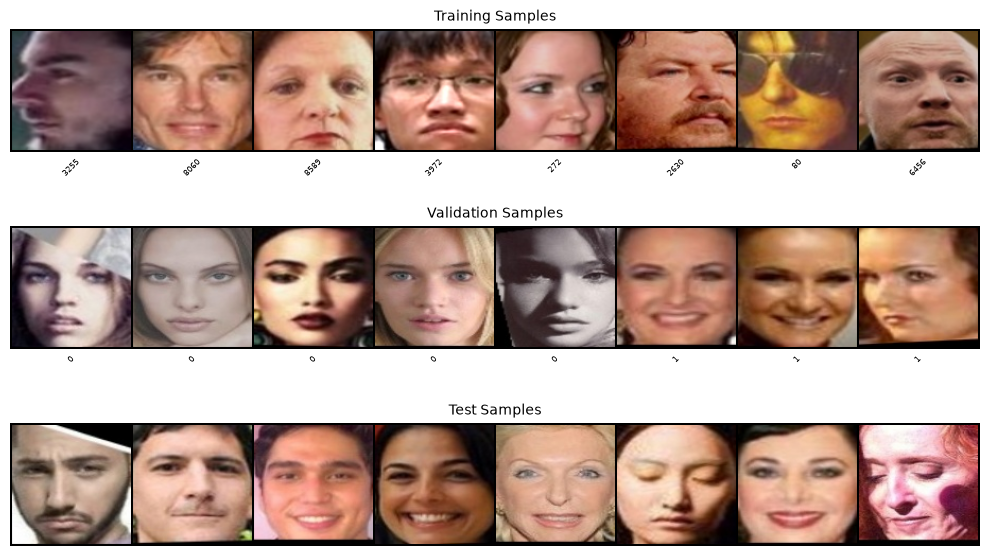

In [13]:
def show_cls_dataset_samples(train_loader, val_loader, test_loader, samples_per_set=8, figsize=(10, 6)):
    """
    Display samples from train, validation, and test datasets side by side

    Args:
        train_loader: Training data loader
        val_loader: Validation data loader
        test_loader: Test data loader
        samples_per_set: Number of samples to show from each dataset
        figsize: Figure size (width, height)
    """
    def denormalize(x):
        """Denormalize images from [-1, 1] to [0, 1]"""
        return x * 0.5 + 0.5

    def get_samples(loader, n, labeled=True):
        """Get n samples from a dataloader"""
        batch = next(iter(loader))

        if labeled:
            return batch[0][:n], batch[1][:n]
        else:
            return batch[:n], None

    # Get samples from each dataset
    train_imgs, train_labels = get_samples(train_loader, samples_per_set, labeled=True)
    val_imgs, val_labels = get_samples(val_loader, samples_per_set, labeled=True)
    test_imgs, test_labels = get_samples(test_loader, samples_per_set, labeled=False)

    # Create figure
    fig, axes = plt.subplots(3, 1, figsize=figsize)

    # Plot each dataset
    for idx, (imgs, labels, title) in enumerate([
        (train_imgs, train_labels, 'Training Samples'),
        (val_imgs, val_labels, 'Validation Samples'),
        (test_imgs, test_labels, 'Test Samples')
    ]):

        # Create grid of images
        grid = make_grid(denormalize(imgs), nrow=8, padding=2)

        # Display grid
        axes[idx].imshow(grid.permute(1, 2, 0).cpu())
        axes[idx].axis('off')
        axes[idx].set_title(title, fontsize=10)

        # Add class labels below images (with smaller font)
        grid_width = grid.shape[2]
        imgs_per_row = min(8, samples_per_set)
        img_width = grid_width // imgs_per_row

        if labels is not None:
            for i, label in enumerate(labels):
                col = i % imgs_per_row

                if label < len(train_loader.dataset.classes):
                    class_name = train_loader.dataset.classes[label]
                else:
                    class_name = f"Class {label} (Unknown)"

                axes[idx].text(
                    col * img_width + img_width/2,
                    grid.shape[1] + 5,
                    class_name,
                    ha='center',
                    va='top',
                    fontsize=6,
                    rotation=45
                )

    plt.tight_layout()
    plt.show()

show_cls_dataset_samples(cls_train_loader, cls_val_loader, cls_test_loader)

### Ver Dataset Viz

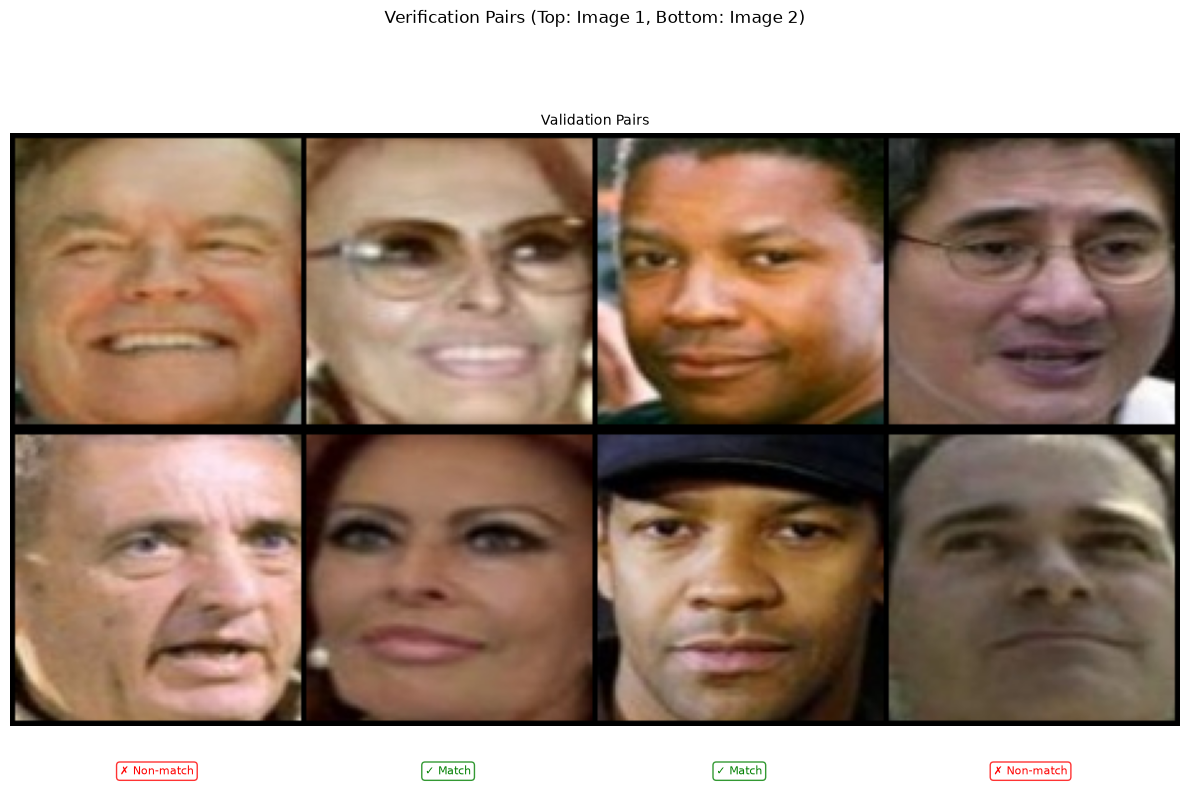

In [14]:
import matplotlib.pyplot as plt
import torch
from torchvision.utils import make_grid

def show_ver_dataset_samples(val_loader, samples_per_set=4, figsize=(12, 8)):
    """
    Display verification pairs from the validation dataset

    Args:
        val_loader: Validation data loader
        samples_per_set: Number of pairs to show from the dataset
        figsize: Figure size (width, height)
    """
    def denormalize(x):
        """Denormalize images from [-1, 1] to [0, 1]"""
        return x * 0.5 + 0.5

    def get_samples(loader, n):
        """Get n samples from a dataloader"""
        batch = next(iter(loader))
        return batch[0][:n], batch[1][:n], batch[2][:n]

    # Get samples from the validation dataset
    val_imgs1, val_imgs2, val_labels = get_samples(val_loader, samples_per_set)

    # Create figure and axis
    fig, ax = plt.subplots(1, 1, figsize=figsize)

    # Create grids for both images in each pair
    grid1 = make_grid(denormalize(val_imgs1), nrow=samples_per_set, padding=2)
    grid2 = make_grid(denormalize(val_imgs2), nrow=samples_per_set, padding=2)

    # Combine the grids vertically
    combined_grid = torch.cat([grid1, grid2], dim=1)

    # Display the combined grid
    ax.imshow(combined_grid.permute(1, 2, 0).cpu())
    ax.axis('off')
    ax.set_title('Validation Pairs', fontsize=10)

    # Determine dimensions for placing the labels
    grid_width = grid1.shape[2]
    img_width = grid_width // samples_per_set

    # Add match/non-match labels for each pair
    for i, label in enumerate(val_labels):
        match_text = "✓ Match" if label == 1 else "✗ Non-match"
        color = 'green' if label == 1 else 'red'

        # Define a background box for the label
        bbox_props = dict(
            boxstyle="round,pad=0.3",
            fc="white",
            ec=color,
            alpha=0.8
        )

        ax.text(i * img_width + img_width / 2,
                combined_grid.shape[1] + 15,  # Position below the images
                match_text,
                ha='center',
                va='top',
                fontsize=8,
                color=color,
                bbox=bbox_props)

    plt.suptitle("Verification Pairs (Top: Image 1, Bottom: Image 2)", y=1.02)
    plt.tight_layout()
    plt.subplots_adjust(bottom=0.05)
    plt.show()

show_ver_dataset_samples(ver_val_loader)


# Model Architecture

## FAQ

### **What is the “very low early-deadline architecture” (mandatory early submission)?**

The *very low early-deadline architecture* is a simple **5-layer convolutional neural network (CNN)** designed to meet the early-submission requirements. Remember that the **maximum parameter budget for this homework is 30 million parameters**.

**Architecture details:**

* The network consists of **5 convolutional layers**.
* The **first convolutional layer**:

  * Output channels: **64**
  * Kernel size: **7**
  * Stride: **4**
* The **next four convolutional layers** have:

  * Output channels: **128 → 256 → 512 → 1024**
  * Kernel size: **3**
  * Stride: **2**
* Each convolutional layer is followed by:

  * **Batch Normalization**
  * **ReLU activation**

For creating convolutional layers, refer to the PyTorch documentation:
[https://pytorch.org/docs/stable/generated/torch.nn.Conv2d.html](https://pytorch.org/docs/stable/generated/torch.nn.Conv2d.html)

**Strided convolutions and padding:**

* Recall from lecture that a strided convolution can be viewed as a stride-1 convolution followed by downsampling.
* To preserve spatial alignment when using strided convolutions, choose:

  ```
  padding = kernel_size // 2
  ```
* Think about *why* this works: symmetric padding ensures the convolution remains centered over the input.

**Final pooling and flattening:**

* After the convolutional layers, apply **Adaptive Average Pooling** to reduce the spatial dimensions to **1 × 1**:

  * Use `AdaptiveAvgPool2d((1, 1))`
  * Documentation: [https://pytorch.org/docs/stable/generated/torch.nn.AdaptiveAvgPool2d.html](https://pytorch.org/docs/stable/generated/torch.nn.AdaptiveAvgPool2d.html)
* Finally, remove the trivial spatial dimensions (e.g., using `Flatten`).

For more layer options, see:
[https://pytorch.org/docs/stable/nn.html](https://pytorch.org/docs/stable/nn.html)

---

### **Why does this simple network use multiple downsampling convolutions?**

The input images are **112 × 112**. Each convolutional layer performs spatial downsampling.

* Downsampling by **2×** effectively **doubles the receptive field**, allowing neurons to capture information from a larger region of the image.
* Downsampling by **32×** in total is standard in many modern image models and provides a good balance between spatial resolution and semantic abstraction.

---

### **Why does this simple network use large channel sizes?**

Each time the spatial resolution is downsampled by **2×**, the computational cost drops by **4×** (assuming the number of channels stays constant).

To compensate:

* The number of channels is increased by **2×**, which increases computation by **4×**
* This keeps the overall computation roughly balanced across layers

Another intuition:

* As spatial resolution decreases, some spatial information is lost
* Increasing the number of channels helps preserve this information in the **feature (channel) dimension**

---


In [ ]:
class SEModule(nn.Module):
    """
    Squeeze-and-Excitation: global-average-pool each channel ("squeeze"), pass through a small
    bottleneck MLP and a sigmoid ("excitation"), then rescale the channels. Lets the block
    emphasize the feature maps that matter for this face. ~1% extra parameters.
    """

    def __init__(self, channels: int, reduction: int = 16):
        super().__init__()
        self.fc = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Conv2d(channels, channels // reduction, kernel_size=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(channels // reduction, channels, kernel_size=1),
            nn.Sigmoid(),
        )

    def forward(self, x):
        return x * self.fc(x)


def drop_path(x, p: float, training: bool):
    """Stochastic depth: during training, zero the whole residual branch for a random subset of samples."""
    if not training or p == 0.0:
        return x
    keep = 1.0 - p
    mask = x.new_empty(x.shape[0], 1, 1, 1).bernoulli_(keep)
    return x * mask / keep


class BasicBlock(nn.Module):
    """
    ResNet basic block: conv3x3-BN-ReLU-conv3x3-BN plus identity skip.
    When the block downsamples (stride 2) or widens, the skip uses a 1x1 strided conv + BN.
    """

    def __init__(self, in_ch: int, out_ch: int, stride: int = 1, se: bool = False, drop_path: float = 0.0):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_ch)
        self.relu = nn.ReLU(inplace=True)
        self.se = SEModule(out_ch) if se else None
        self.drop_path = drop_path

        self.shortcut = nn.Identity()
        if stride != 1 or in_ch != out_ch:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_ch, out_ch, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(out_ch),
            )

    def forward(self, x):
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        if self.se is not None:
            out = self.se(out)
        out = drop_path(out, self.drop_path, self.training)
        return self.relu(out + self.shortcut(x))


class NormLinear(nn.Module):
    """
    Cosine classifier: logits = s * cos(theta) between the L2-normalized embedding and
    L2-normalized class weights. The ArcFace loss adds the angular margin during training.
    """

    def __init__(self, in_features: int, num_classes: int, s: float):
        super().__init__()
        self.s = s
        self.weight = nn.Parameter(torch.empty(num_classes, in_features))
        nn.init.xavier_uniform_(self.weight)

    def forward(self, x):
        # fp32 outside autocast: ArcFace needs precise cosines near 1
        with torch.autocast(device_type=x.device.type, enabled=False):
            cos = F.linear(F.normalize(x.float(), dim=1), F.normalize(self.weight.float(), dim=1))
        return self.s * cos


class Network(nn.Module):
    """
    ResNet-34-style backbone for 112x112 faces.

    112 --stem s1--> 112 --stage1 s2--> 56 --stage2 s2--> 28 --stage3 s2--> 14 --stage4 s2--> 7
    The stem keeps full resolution (faces are small; run one's stride-4 stem threw detail away),
    and each stage halves resolution while doubling channels (constant compute per stage).
    """

    def __init__(self, num_classes: int, blocks=(3, 4, 6, 3), channels=(64, 128, 256, 512),
                 embedding_dim: int = 512, dropout: float = 0.2, s: float = 32.0,
                 se: bool = False, drop_path: float = 0.0):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(3, channels[0], kernel_size=3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(channels[0]),
            nn.ReLU(inplace=True),
        )

        stages = []
        in_ch = channels[0]
        # Stochastic depth grows linearly with depth: early blocks are almost never dropped
        n_total = sum(blocks)
        dp = [drop_path * i / max(1, n_total - 1) for i in range(n_total)]
        k = 0
        for n_blocks, out_ch in zip(blocks, channels):
            layers = []
            for b in range(n_blocks):
                layers.append(BasicBlock(in_ch if b == 0 else out_ch, out_ch, stride=2 if b == 0 else 1, se=se, drop_path=dp[k]))
                k += 1
            stages.append(nn.Sequential(*layers))
            in_ch = out_ch
        self.stages = nn.Sequential(*stages)

        self.pool = nn.Sequential(nn.AdaptiveAvgPool2d((1, 1)), nn.Flatten())

        # Embedding head: Dropout -> Linear -> BN1d (the BN-normalized vector is the face embedding)
        self.embedding = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(in_ch, embedding_dim, bias=False),
            nn.BatchNorm1d(embedding_dim),
        )
        self.cls_layer = NormLinear(embedding_dim, num_classes, s=s)

        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
        # Zero-init the last BN of each residual branch so every block starts as identity
        for m in self.modules():
            if isinstance(m, BasicBlock):
                nn.init.zeros_(m.bn2.weight)

    def forward(self, x, return_feats: bool = False):
        """
        Args:
            x (Tensor): Input image batch of shape (B, 3, H, W)
            return_feats (bool): If True, return only feature embeddings

        Returns:
            dict with keys:
                - 'feats': feature embeddings (used for verification)
                - 'out': classification logits, s * cos(theta)
        """
        feats = self.embedding(self.pool(self.stages(self.stem(x))))

        if return_feats:
            return feats

        out = self.cls_layer(feats)
        return {"feats": feats, "out": out}


class FlipTTA(nn.Module):
    """
    Test-time augmentation for inference: runs the model on the image and its mirror.
    Embeddings are summed (after L2-normalizing each) and logits averaged.
    Exposes the same {'feats', 'out'} dict, so the course submission utils work unchanged.
    """

    def __init__(self, model):
        super().__init__()
        self.model = model

    @torch.no_grad()
    def forward(self, x):
        a = self.model(x)
        b = self.model(torch.flip(x, dims=[3]))
        feats = F.normalize(a["feats"], dim=1) + F.normalize(b["feats"], dim=1)
        return {"feats": feats, "out": (a["out"] + b["out"]) / 2}


# Initialize model
model = Network(
    num_classes=config["num_classes"],
    blocks=config["blocks"],
    channels=config["channels"],
    embedding_dim=config["embedding_dim"],
    dropout=config["dropout"],
    s=config["arcface_s"],
    se=config.get("se", False),
    drop_path=config.get("drop_path", 0.0),
).to(DEVICE).to(memory_format=torch.channels_last)

n_params = sum(p.numel() for p in model.parameters())
print(f"Total params: {n_params:,}")
assert n_params < 30_000_000, "Over the 30M parameter limit"

# Optional: model summary (eval mode: summary libraries feed a dummy batch as small as 1,
# and the BatchNorm1d in the embedding head can't train on a single sample)
model.eval()
summary(model, (3, 112, 112))
model.train()

# Loss | Optimizer | Scheduler

In [ ]:
import math

# ---------------------------------------------------
# Loss Function
# ---------------------------------------------------

class ArcFaceLoss(nn.Module):
    """
    Additive angular margin loss (ArcFace, writeup section 5.6.2).
    Takes the cosine-classifier logits s*cos(theta) and replaces the target logit
    with s*cos(theta_y + m), so the true class must win by an angular margin m.
    `m` is a plain attribute so the training loop can ramp it up.
    """

    def __init__(self, s: float, m: float, label_smoothing: float = 0.0):
        super().__init__()
        self.s = s
        self.m = m
        self.ce = nn.CrossEntropyLoss(label_smoothing=label_smoothing)

    def forward(self, logits, labels):
        cos = (logits.float() / self.s).clamp(-1 + 1e-7, 1 - 1e-7)
        cos_m, sin_m = math.cos(self.m), math.sin(self.m)
        sin = torch.sqrt(1.0 - cos * cos)
        phi = cos * cos_m - sin * sin_m  # cos(theta + m)
        # When theta + m > pi, cos(theta + m) stops being monotonic; fall back to a CosFace-style penalty
        phi = torch.where(cos > math.cos(math.pi - self.m), phi, cos - math.sin(math.pi - self.m) * self.m)

        one_hot = F.one_hot(labels, num_classes=cos.size(1)).bool()
        margin_logits = self.s * torch.where(one_hot, phi, cos)
        return self.ce(margin_logits, labels)


# ArcFace already enforces a margin on clean one-hot targets; label smoothing / mixup / cutmix conflict with it
assert config['label_smoothing'] == 0.0, "Do not use label smoothing with ArcFace"
criterion = ArcFaceLoss(s=config['arcface_s'], m=0.0, label_smoothing=config['label_smoothing'])

def margin_at(epoch):
    """Linearly ramp the ArcFace margin from 0 to arcface_m over margin_warmup_epochs."""
    warm = config['margin_warmup_epochs']
    return config['arcface_m'] * min(1.0, (epoch + 1) / warm) if warm > 0 else config['arcface_m']

# ---------------------------------------------------
# Optimizer
# ---------------------------------------------------

# SGD with Nesterov momentum. Weight decay only on conv/linear weights:
# decaying BatchNorm scales and biases fights normalization and hurts accuracy.
decay, no_decay = [], []
for name, p in model.named_parameters():
    (no_decay if p.ndim <= 1 else decay).append(p)
optimizer = optim.SGD(
    [{'params': decay, 'weight_decay': config['weight_decay']},
     {'params': no_decay, 'weight_decay': 0.0}],
    lr=config['lr'], momentum=0.9, nesterov=True,
)

# ---------------------------------------------------
# Weight EMA
# ---------------------------------------------------

# Keeps an exponential moving average of the weights (and BatchNorm statistics), updated every step.
# The average sits in a flatter, better-generalizing region than the last SGD iterate; it is what we
# validate, checkpoint as the best model and submit. The raw model keeps training as usual.
from torch.optim.swa_utils import AveragedModel, get_ema_multi_avg_fn
ema = AveragedModel(model, multi_avg_fn=get_ema_multi_avg_fn(config['ema_decay']), use_buffers=True) if config.get('ema_decay') else None

# ---------------------------------------------------
# Learning Rate Scheduler
# ---------------------------------------------------

# Linear warmup then cosine decay to 0, stepped once per BATCH (smoother than per epoch).
# Warmup keeps the high LR from destabilizing the freshly initialized deep network.
steps_per_epoch = len(cls_train_loader)
warmup_steps = config['warmup_epochs'] * steps_per_epoch
total_steps = config['epochs'] * steps_per_epoch

def lr_lambda(step):
    if step < warmup_steps:
        return (step + 1) / warmup_steps
    progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
    return 0.5 * (1.0 + math.cos(math.pi * progress))

scheduler = optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)

# ---------------------------------------------------
# Mixed-Precision Training (FP16)
# ---------------------------------------------------

# GradScaler enables stable mixed-precision training on supported GPUs (e.g., T4, V100).
# This reduces memory usage and can significantly speed up training.
scaler = torch.amp.GradScaler(device='cuda')

# Metrics

In [17]:
class AverageMeter:
    """
    Tracks and computes the running average of a scalar metric.
    """

    def __init__(self):
        self.reset()

    def reset(self):
        self.val = 0.0
        self.avg = 0.0
        self.sum = 0.0
        self.count = 0

    def update(self, val, n: int = 1):
        self.val = float(val)
        self.sum += val * n
        self.count += n
        self.avg = self.sum / max(self.count, 1)


def topk_accuracy(logits: torch.Tensor, targets: torch.Tensor, topk=(1,)):
    """
    Computes top-k accuracy for the given logits and targets.

    Args:
        logits (Tensor): Model outputs of shape (B, C)
        targets (Tensor): Ground-truth labels of shape (B,)
        topk (tuple): Values of k for top-k accuracy

    Returns:
        List[Tensor]: Accuracy values in percentage for each k
    """
    maxk = min(max(topk), logits.size(1))
    batch_size = targets.size(0)

    _, preds = logits.topk(maxk, dim=1, largest=True, sorted=True)
    preds = preds.t()
    correct = preds.eq(targets.view(1, -1))

    accuracies = []
    for k in topk:
        k = min(k, maxk)
        correct_k = correct[:k].reshape(-1).float().sum(0)
        accuracies.append(correct_k * 100.0 / batch_size)

    return accuracies


def verification_metrics(labels, scores, fpr_targets=None):
    """
    Computes standard verification metrics: ACC, EER, AUC, and TPR@FPR.

    Args:
        labels (list or array): Binary labels (0 or 1)
        scores (list or array): Similarity scores
        fpr_targets (list, optional): Target FPR values for reporting TPR

    Returns:
        dict: Verification metrics
    """
    labels = np.asarray(labels)
    scores = np.asarray(scores)

    # TODO: Compute verificaion metrics
    # Hint: Read the documentation for sklearn.metrics.roc_curve
    # and use it to compute fpr and tpr
    fpr, tpr, _ = mt.roc_curve(labels, scores, pos_label=1)

    # Hint: You can use interp1d from scipy.interpolate to create roc_interp
    roc_interp = interp1d(fpr, tpr, bounds_error=False, fill_value=(0.0, 1.0))

    # Equal Error Rate (EER)
    # Hint: You might find brentq from scipy.optimize helpful to compute EER
    eer = 100.0 * brentq(lambda x: 1.0 - x - roc_interp(x), 0.0, 1.0)

    # Area Under Curve (AUC)
    # Hint: Use mt.auc to compute AUC
    # Be careful to multiply by 100.0 to express as percentage
    auc = 100.0 * mt.auc(fpr, tpr)

    # Accuracy (best threshold)
    # TODO: Compute TNR, pos_count, neg_count, and accuracy
    # Hint: Use fpr and tpr to compute TNR
    # Hint: pos_count is the number of positive labels (1s)
    # Hint: neg_count is the number of negative labels (0s)
    tnr = 1.0 - fpr
    pos_count = np.sum(labels == 1)
    neg_count = np.sum(labels == 0)
    acc = 100.0 * float(np.max(tpr * pos_count + tnr * neg_count)) / len(labels)

    # TPR @ specific FPRs
    tpr_at_fpr = []
    if fpr_targets is not None:
        for fpr_val in fpr_targets:
            tpr_at_fpr.append(
                (f"TPR@FPR={fpr_val}", 100.0 * float(roc_interp(fpr_val)))
            )

    return {
        "ACC": acc,
        "EER": eer,
        "AUC": auc,
        "TPRs": tpr_at_fpr,
    }


# Train and Validation Function

In [ ]:
def train_epoch(
    model,
    dataloader,
    optimizer,
    scaler,
    device,
    criterion,
    scheduler=None,
    ema=None,
):
    """
    Runs one training epoch.

    Args:
        model (nn.Module): Model to train
        dataloader (DataLoader): Training dataloader
        optimizer (Optimizer): Optimizer
        scaler (GradScaler): AMP gradient scaler
        device (torch.device): Training device
        criterion (callable): Loss function
        scheduler (LRScheduler, optional): Stepped once per batch
        ema (AveragedModel, optional): Weight EMA, updated after every optimizer step

    Returns:
        tuple: (avg_accuracy, avg_loss)
    """
    model.train()

    loss_meter = AverageMeter()
    acc_meter = AverageMeter()

    progress = tqdm(
        dataloader,
        desc="Train",
        dynamic_ncols=True,
        leave=False,
    )

    for images, labels in progress:
        optimizer.zero_grad(set_to_none=True)

        # Move data to device
        images = images.to(device, non_blocking=True)

        if isinstance(labels, (tuple, list)):
            # For mixup / cutmix style labels
            targets1, targets2, lam = labels
            labels = (
                targets1.to(device, non_blocking=True),
                targets2.to(device, non_blocking=True),
                lam,
            )
        else:
            labels = labels.to(device, non_blocking=True)

        # Forward pass (mixed precision)
        with torch.amp.autocast(device_type = 'cuda'):
            outputs = model(images)
            logits = outputs["out"]
            loss = criterion(logits, labels)

        # Backward + optimizer step (AMP-safe)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        if scheduler is not None:
            scheduler.step()
        if ema is not None:
            ema.update_parameters(model)

        # Metrics
        batch_loss = loss.item()
        loss_meter.update(batch_loss)

        with torch.no_grad():
            batch_acc = topk_accuracy(logits, labels, topk=(1,))[0].item()
            acc_meter.update(batch_acc)

        # Progress bar update
        progress.set_postfix(
            loss=f"{batch_loss:.4f} ({loss_meter.avg:.4f})",
            acc=f"{batch_acc:.2f}% ({acc_meter.avg:.2f}%)",
            lr=f"{optimizer.param_groups[0]['lr']:.6f}",
        )

    return acc_meter.avg, loss_meter.avg

In [19]:
@torch.no_grad()
def valid_epoch_cls(
    model,
    dataloader,
    device,
    criterion,
):
    """
    Runs one validation epoch for classification.

    Args:
        model (nn.Module): Trained model
        dataloader (DataLoader): Validation dataloader
        device (torch.device): Evaluation device
        criterion (callable): Loss function

    Returns:
        tuple: (avg_accuracy, avg_loss)
    """
    model.eval()

    loss_meter = AverageMeter()
    acc_meter = AverageMeter()

    progress = tqdm(
        dataloader,
        desc="Val (Cls)",
        dynamic_ncols=True,
        leave=False,
    )

    for images, labels in progress:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        # Forward pass (inference-only)
        outputs = model(images)
        logits = outputs["out"]
        loss = criterion(logits, labels)

        # Metrics
        batch_loss = loss.item()
        loss_meter.update(batch_loss)

        batch_acc = topk_accuracy(logits, labels, topk=(1,))[0].item()
        acc_meter.update(batch_acc)

        # Progress bar update
        progress.set_postfix(
            loss=f"{batch_loss:.4f} ({loss_meter.avg:.4f})",
            acc=f"{batch_acc:.2f}% ({acc_meter.avg:.2f}%)",
        )

    return acc_meter.avg, loss_meter.avg


In [20]:
gc.collect() # These commands help you when you face CUDA OOM error
torch.cuda.empty_cache()

# Verification Task

In [21]:
@torch.no_grad()
def valid_epoch_ver(model, pair_dataloader, device, fpr_targets=None):
    """
    Runs one validation epoch for verification (image pairs).

    Args:
        model (nn.Module): Trained model
        pair_dataloader (DataLoader): DataLoader yielding (img1, img2, label) tuples
        device (torch.device): Evaluation device
        fpr_targets (list, optional): List of FPRs for TPR reporting

    Returns:
        dict: Verification metrics including ACC, EER, AUC, TPR@FPR
    """
    model.eval()
    scores = []
    match_labels = []

    progress = tqdm(
        pair_dataloader,
        desc="Val (Veri)",
        dynamic_ncols=True,
        leave=False,
    )

    for images1, images2, labels in progress:
        # Move data to device
        images1 = images1.to(device, non_blocking=True)
        images2 = images2.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        # Forward pass
        images = torch.cat([images1, images2], dim=0)
        outputs = model(images)
        feats = F.normalize(outputs["feats"], dim=1)

        # Split features and compute similarity
        feats1, feats2 = feats.chunk(2, dim=0)
        similarity = F.cosine_similarity(feats1, feats2, dim=1)

        # Accumulate results
        scores.append(similarity.cpu().numpy())
        match_labels.append(labels.cpu().numpy())

        progress.update()

    # Concatenate batch-wise results
    scores = np.concatenate(scores)
    match_labels = np.concatenate(match_labels)

    # Default FPR targets if not provided
    if fpr_targets is None:
        fpr_targets = [1e-4, 5e-4, 1e-3, 5e-3, 5e-2]

    # Compute verification metrics
    metric_dict = verification_metrics(match_labels, scores, fpr_targets)

    # Optional: print metrics
    print("Verification Metrics:", metric_dict)

    return metric_dict


# WandB

In [22]:
wandb.login(key=ENV['WANDB_API_KEY']) # API Key is in your wandb account, under settings (wandb.ai/settings)

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: Appending key for api.wandb.ai to your netrc file: C:\Users\jrzem\_netrc
wandb: Currently logged in as: jzembowe (jzembowe-carnegie-mellon-university) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


True

In [ ]:
# Create your wandb run. The run id is stored in the run's checkpoint folder,
# so re-running this cell in a new PSC session resumes the same wandb run.
wandb_id_path = os.path.join(config['checkpoint_dir'], "wandb_run_id.txt")
if config['resume'] and os.path.exists(wandb_id_path):
    wandb_run_id = open(wandb_id_path).read().strip()
else:
    wandb_run_id = wandb.util.generate_id()
    with open(wandb_id_path, "w") as f:
        f.write(wandb_run_id)

run = wandb.init(
    name = config['run_name'],
    id = wandb_run_id,
    resume = "allow",
    project = "hw2p2", ### Project should be created in your wandb account
    config = config ### Wandb Config for your run
)

# Checkpointing and Loading Model

In [ ]:
# Ensure checkpoint directory exists (one folder per run: checkpoints/<run_name>/)
checkpoint_dir = config["checkpoint_dir"]
os.makedirs(checkpoint_dir, exist_ok=True)


def save_model(model, optimizer, scheduler, metrics, epoch, path, ema=None):
    """
    Saves model, optimizer, scheduler, and training metrics to a checkpoint.

    Args:
        model (nn.Module): Model to save
        optimizer (Optimizer): Optimizer
        scheduler (LRScheduler): Learning rate scheduler
        metrics (dict): Dictionary of tracked metrics
        epoch (int): Current epoch
        path (str): Path to save checkpoint
        ema (AveragedModel, optional): Weight EMA; its weights are stored as 'ema_state_dict'
    """
    torch.save(
        {
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict() if optimizer is not None else None,
            "scheduler_state_dict": scheduler.state_dict() if scheduler is not None else None,
            "metrics": metrics,
            "epoch": epoch,
            "config": config,
            "ema_state_dict": ema.module.state_dict() if ema is not None else None,
        },
        path,
    )
    print(f"Checkpoint saved at {path}")


def load_model(model, optimizer=None, scheduler=None, path="./checkpoint.pth", device=None):
    """
    Loads model, optimizer, scheduler, and metrics from a checkpoint.

    Args:
        model (nn.Module): Model to load weights into
        optimizer (Optimizer, optional): Optimizer to load state
        scheduler (LRScheduler, optional): Scheduler to load state
        path (str): Path to checkpoint file
        device (torch.device, optional): Device mapping for checkpoint

    Returns:
        tuple: model, optimizer, scheduler, epoch, metrics
    """
    map_location = device if device is not None else "cpu"
    checkpoint = torch.load(path, map_location=map_location)

    model.load_state_dict(checkpoint["model_state_dict"])

    if optimizer is not None and checkpoint.get("optimizer_state_dict") is not None:
        optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

    if scheduler is not None and checkpoint.get("scheduler_state_dict") is not None:
        scheduler.load_state_dict(checkpoint["scheduler_state_dict"])

    epoch = checkpoint.get("epoch", 0)
    metrics = checkpoint.get("metrics", {})

    print(f"Checkpoint loaded from {path} (epoch {epoch})")
    return model, optimizer, scheduler, epoch, metrics

# Experiments

In [ ]:
# Training setup
start_epoch = 0
best_cls_acc = 0.0
best_ret_acc = 0.0
best_combined_score = 0.0

# Resume from this run's last checkpoint (never from another run's folder)
last_path = os.path.join(config["checkpoint_dir"], "last.pth")
if config["resume"] and os.path.exists(last_path):
    model, optimizer, scheduler, last_epoch, last_metrics = load_model(
        model, optimizer, scheduler, path=last_path, device=DEVICE
    )
    if ema is not None:
        ckpt = torch.load(last_path, map_location="cpu")  # CPU: don't hold a second copy of the checkpoint on the GPU
        ema.module.load_state_dict(ckpt["ema_state_dict"])
        del ckpt
        ema.n_averaged.fill_(1)  # >0, so the next update averages instead of overwriting with the raw weights
    start_epoch = last_epoch + 1
    best_cls_acc = last_metrics.get("best_cls_acc", 0.0)
    best_ret_acc = last_metrics.get("best_ret_acc", 0.0)
    best_combined_score = last_metrics.get("best_combined_score", 0.0)
    print(f"Resuming {config['run_name']} at epoch {start_epoch + 1}")

for epoch in range(start_epoch, config["epochs"]):
    print(f"\n=== Epoch {epoch + 1}/{config['epochs']} ===")

    curr_lr = optimizer.param_groups[0]["lr"]
    criterion.m = margin_at(epoch)
    # -----------------------------
    # Train (scheduler steps every batch inside train_epoch)
    # -----------------------------
    train_cls_acc, train_loss = train_epoch(
        model, cls_train_loader, optimizer, scaler, DEVICE, criterion, scheduler, ema
    )
    print(
        f"Train | Cls Acc: {train_cls_acc:.4f}% | Loss: {train_loss:.4f} | LR: {curr_lr:.6f} | Margin: {criterion.m:.3f}"
    )

    metrics = {
        "train_cls_acc": train_cls_acc,
        "train_loss": train_loss,
        "lr": curr_lr,
        "arcface_m": criterion.m,
    }

    # Validate (and pick the best checkpoint by) the EMA weights when EMA is on
    eval_model = ema.module if ema is not None else model

    # -----------------------------
    # Classification Validation
    # -----------------------------
    valid_cls_acc, valid_loss = valid_epoch_cls(
        eval_model, cls_val_loader, DEVICE, criterion
    )

    print(f"Val (Cls) | Acc: {valid_cls_acc:.4f}% | Loss: {valid_loss:.4f}")

    metrics.update({
        "valid_cls_acc": valid_cls_acc,
        "valid_loss": valid_loss,
    })

    # -----------------------------
    # Verification / Retrieval Validation
    # -----------------------------
    valid_ret_metrics = valid_epoch_ver(eval_model, ver_val_loader, DEVICE)
    valid_ret_acc = valid_ret_metrics["ACC"]
    valid_eer = valid_ret_metrics["EER"]
    print(f"Val (Veri) | ACC: {valid_ret_acc:.4f}% | EER: {valid_eer:.4f}%")
    metrics.update({
        "valid_ret_acc": valid_ret_acc,
        "valid_eer": valid_eer,
    })

    # -----------------------------
    # Combined Score Calculation
    # -----------------------------
    valid_combined_score = 0.5 * valid_cls_acc + 0.5 * (100.0 - valid_eer)
    print(f"Val (Combined) | Score: {valid_combined_score:.4f}%")
    metrics.update({
        "valid_combined_score": valid_combined_score
    })

    # -----------------------------
    # Log metrics
    # -----------------------------
    if "run" in globals() and run is not None:
        run.log(metrics, step=epoch)

    # -----------------------------
    # Save checkpoints (all inside checkpoints/<run_name>/)
    # -----------------------------
    # Save best classification model
    if valid_cls_acc >= best_cls_acc:
        best_cls_acc = valid_cls_acc
        best_cls_path = os.path.join(config["checkpoint_dir"], "best_cls.pth")
        save_model(model, optimizer, scheduler, metrics, epoch, best_cls_path, ema)
        print(f"Saved best classification model: {best_cls_path}")

    # Save best retrieval model
    if valid_ret_acc >= best_ret_acc:
        best_ret_acc = valid_ret_acc
        best_ret_path = os.path.join(config["checkpoint_dir"], "best_ret.pth")
        save_model(model, optimizer, scheduler, metrics, epoch, best_ret_path, ema)
        print(f"Saved best retrieval model: {best_ret_path}")

    # Save best combined model
    if valid_combined_score >= best_combined_score:
        best_combined_score = valid_combined_score
        best_combined_path = os.path.join(config["checkpoint_dir"], "best_combined.pth")
        save_model(model, optimizer, scheduler, metrics, epoch, best_combined_path, ema)
        if "run" in globals() and run is not None:
            wandb.save(best_combined_path, base_path=os.path.dirname(config["checkpoint_dir"]))
        print(f"Saved best combined model: {best_combined_path}")

    # Last checkpoint carries the running bests so a resumed session continues correctly
    metrics.update({
        "best_cls_acc": best_cls_acc,
        "best_ret_acc": best_ret_acc,
        "best_combined_score": best_combined_score,
    })
    save_model(model, optimizer, scheduler, metrics, epoch, last_path, ema)
    print(f"Saved last epoch model: {last_path}")

# Inference & Submission

## Kaggle Submission Instructions

* Run the code block below to **automatically generate** the submission file for the competition.

In [ ]:
#### DO NOT MODIFY ####
import os, shutil, subprocess
if not os.path.isdir("utils"):  # fetch once; cross-platform replacement for !mv / !rm
    subprocess.run(["git", "clone", "https://github.com/CMU-IDeeL/HW2P2-Student-Utils.git"], check=True)
    shutil.move("HW2P2-Student-Utils/utils", "utils")
    shutil.rmtree("HW2P2-Student-Utils", ignore_errors=True)
from utils import (
    run_cls_inference_file_order,
    run_ver_inference,
    write_submission_bundle,
)

# Training is finished: free the optimizer state, EMA copy and cached blocks before inference
for _name in ("optimizer", "scheduler", "scaler", "ema"):
    globals().pop(_name, None)
gc.collect()
torch.cuda.empty_cache()

# Load this run's best combined checkpoint and evaluate with flip TTA
model, _, _, best_epoch, _ = load_model(
    model, path=os.path.join(config["checkpoint_dir"], "best_combined.pth"), device=DEVICE
)
best_ckpt = torch.load(os.path.join(config["checkpoint_dir"], "best_combined.pth"), map_location="cpu")
if best_ckpt.get("ema_state_dict") is not None:
    model.load_state_dict(best_ckpt["ema_state_dict"])  # the EMA weights are the ones that were validated
    print("Using the EMA weights")
del best_ckpt
tta_model = FlipTTA(model).eval()
tta_ver = valid_epoch_ver(tta_model, ver_val_loader, DEVICE)
print(f"Best epoch {best_epoch + 1} | Val EER with flip TTA: {tta_ver['EER']:.4f}%")

cls_predictions = run_cls_inference_file_order(
    model=tta_model,
    cls_test_root=cls_data_dir + "/test",
    transform=val_transforms,
    device=DEVICE,
    batch_size=config["batch_size"],
    logits_key="out",
)

ver_scores = run_ver_inference(
    model=tta_model,
    pair_dataloader=ver_test_loader,
    device=DEVICE,
    embedding_key="feats",
)

submission_rows = write_submission_bundle(
    cls_predictions=cls_predictions,
    ver_scores=ver_scores,
    submission_path=os.path.join(config["checkpoint_dir"], "submission.csv"),
    cls_component_path=os.path.join(config["checkpoint_dir"], "cls_submission.csv"),
    ver_component_path=os.path.join(config["checkpoint_dir"], "ver_submission.csv"),
)

shutil.copy(os.path.join(config["checkpoint_dir"], "submission.csv"), "submission.csv")
print(f"Saved {config['checkpoint_dir']}/submission.csv (copied to ./submission.csv)")
print(f"  Classification predictions: {len(cls_predictions)}")
print(f"  Verification scores:        {len(ver_scores)}")
print(f"  Total rows:                  {len(submission_rows)}")
print(pd.DataFrame(submission_rows).head())

* Preview the merged `submission.csv` file created in the cell above

In [ ]:
submission_preview = pd.read_csv("submission.csv")
print(submission_preview.head())
print(f"Submission rows: {len(submission_preview)}")
print(f"Columns: {list(submission_preview.columns)}")


* Run the code block below to **automatically submit** the generated submission file to the competition.

In [ ]:
api.competition_submit(file_name="submission.csv", message=f"{config['run_name']}: ResNet-34{' SE' if config.get('se') else ''} + ArcFace(s={config['arcface_s']}, m={config['arcface_m']}), {config['epochs']} ep, drop_path {config.get('drop_path', 0)}, EMA {config.get('ema_decay', 0)}, flip TTA", competition="hw-2-p-2-fall-2026-student-competition")


#### **Manual submission (optional)**

If automatic submission is unavailable, download the CSV and submit it manually using one of the options below.

##### **Kaggle**

* After running the cell above, the file **`submission.csv`** will be saved in:
  **Right sidebar → Output → `kaggle/working/`**
* If the file does not appear right away, click the **refresh icon** in the top-right corner of the Output panel.
* Once the file is visible, **right-click → Download**.
* Upload the downloaded file to the **Kaggle competition submission page**.

---

##### **Colab**

```python
from google.colab import files
files.download("submission.csv")
```

##### **PSC**

* Open the left file browser.
* Navigate to:
  `/jet/home/<your_username>/`
* Locate **`submission.csv`**.
* Right-click the file and select **Download**.
* If the file does not appear immediately, refresh the file browser.

## 📦 Gradescope Submission Instructions (Read Carefully)

This section guides you through creating and submitting your **final Gradescope code submission**.
Please follow each step in order. Skipping steps may result in an incomplete or invalid submission.

### ⏰ Important Deadlines

* **Kaggle Final Deadline:** See the course schedule
* **Gradescope Code Submission Deadline:**
  **48 hours after** the Kaggle deadline (or the same day as your Slack Kaggle submission, if applicable)

You must submit **both**:

1. A valid Kaggle submission
2. A complete Gradescope code submission zip

### Step 1: Generate Your Model Metadata File

Please assign your **final trained model** to the global variable `MODEL`.

We will use this variable to automatically generate a file named
`model_metadata.json`, which records important information about your model (such as parameter count and architecture).

#### 🔴 Important Requirements

* **`MODEL` must be the exact model used for your best Kaggle submission**
* This step is **required** for grading and audit purposes
* If the model does not match your Kaggle submission, your score may be invalidated

#### 🕒 When to Do This

* Run this cell **only after you have finished training** your final model
* Do **not** retrain or modify the model after assigning it to `MODEL`



In [ ]:
# The weights behind the final Kaggle submission: this run's best_combined checkpoint (EMA weights when EMA is on).
# Loaded here so the Gradescope steps work without re-running training or inference.
assert "model" in globals(), "Run the Imports, Config and Model Architecture cells first (they define `config` and `model`)."
_final = torch.load(os.path.join(config["checkpoint_dir"], "best_combined.pth"), map_location="cpu", weights_only=False)
model.load_state_dict(_final["ema_state_dict"] if _final.get("ema_state_dict") is not None else _final["model_state_dict"])
print(f"Loaded {config['run_name']} epoch {_final['epoch'] + 1}: val combined {_final['metrics']['valid_combined_score']:.2f}")
del _final
MODEL = model

### Step 2: Complete the README Section


Fill in the `README` variable with a brief description of your work:

* **Model**: Architecture and key design choices
* **Training Strategy**: Optimizer, scheduler, loss, etc.
* **Augmentations**: If used (omit if not)
* **Notebook Execution**: Any instructions needed to run your notebook

This README will be included in your submission zip.

In [ ]:
README = """
- **Model**: For the model, I built an SE-ResNet-34-style CNN from scratch. It uses BasicBlocks in a [3,4,6,3] layout with channels 64-128-256-512, for about 26.1 million parameters. I moved to a ResNet after my 5-layer baseline (run 1) topped out at 87.33 on Kaggle. Residual connections let the gradient flow through the identity path, so a deeper network still trains well instead of degrading.
For the stem, I used a 3x3 stride-1 conv rather than the usual 7x7 stride-2 with max pool. The faces are only 112x112, so I wanted to keep the full resolution going into the first stage instead of throwing away detail right away. Each stage then downsamples 2x with a strided conv until it reaches a 7x7 map.
I added Squeeze-and-Excitation to each block on my last run. SE pools each channel down to one number, passes that through a small bottleneck, and uses the result to reweight the channels. This lets the network learn which feature maps matter for a given face, and it adds very few parameters.
For the embedding, I used global average pool -> Dropout(0.2) -> Linear(512,512) -> BatchNorm1d, which gives the 512-d face embedding used for verification. The classifier on top is a cosine (normalized-weight) layer, so the logits depend only on the angle between the embedding and each class weight. This is what ArcFace needs.
Finally, I used stochastic depth (drop path) up to 0.1, scaled linearly with depth. It randomly skips whole residual branches during training, so deeper blocks get dropped more often. Since run 3 was longer and the model was bigger, I wanted extra regularization against overfitting.
- **Training Strategy**: First, I switched the loss from plain cross-entropy to ArcFace, an additive angular margin loss, with s=32 and m=0.4. Cross-entropy only has to separate the classes, while verification needs embeddings of the same person to sit close together and different people to sit far apart. Adding a margin to the angle of the true class forces tighter clusters. I warmed the margin up linearly over the first 5 epochs, because applying the full margin to a randomly initialized network can make it hard to start converging.
For the optimizer, I used SGD with Nesterov momentum 0.9 at lr 0.1 and batch 256. SGD with momentum is the standard choice for ResNets on image classification and tends to generalize better than adaptive methods there. Nesterov evaluates the gradient at the look-ahead point, which gives a slightly more stable update.
I also used weight decay of 5e-4, but not on the BatchNorm or bias parameters. Decaying the BN scale and shift terms does not regularize anything meaningful and can just hurt the normalization.
For the schedule, I used a 2-epoch linear warmup and then cosine decay updated per batch, for 70 epochs. Warmup keeps the first steps small while the BatchNorm statistics are still settling at a high learning rate. Cosine decay then lowers the learning rate smoothly so the end of training can settle into a good minimum. I also trained with AMP (mixed precision) to speed up each epoch.
Next, I kept an exponential moving average (EMA) of the weights with decay 0.9998. The EMA weights are the ones I validated, checkpointed, and submitted. Averaging over many recent steps smooths out the noise of the individual SGD updates, so the averaged model usually generalizes slightly better than the raw weights.
For picking the best checkpoint, I scored validation by 0.5*cls_acc + 0.5*(100 - EER). The final task is verification, so I did not want to choose the model on classification accuracy alone.
Finally, at inference I used horizontal-flip test-time augmentation. A face and its mirror image should give the same embedding, so combining both views gives a more stable embedding.
- **Augmentations**: For augmentations, the idea is to perturb the input while keeping the label, so the model learns to treat nearby versions of a face the same way. I used RandomResizedCrop (scale 0.8-1.0), horizontal flip, ColorJitter(0.2), RandomGrayscale (p=0.1), and RandomErasing (p=0.25). I kept the crop scale high so the face stays mostly in frame. Color jitter and grayscale handle differences in lighting and camera, and random erasing mimics occlusion from things like glasses, hands, or hair.
I did not use vertical flip, since upside-down faces never show up in the data and would only make the task harder for no benefit.
- **Notebook Execution**: To run the notebook, set config['run_name']. Checkpoints, the config, and submissions are all saved to checkpoints/<run_name>/. With config['resume']=True, re-running all cells picks up from that run's last.pth and continues the same wandb run.
My final model is run3_seresnet34_ema. Its best epoch was 59 of 70 (EMA weights), with val acc 94.19% and val EER 2.04%, and it scored 96.41 on Kaggle public. I trained it on PSC Bridges-2 (V100) as two batch jobs, since the first job hit the time limit and the second resumed from the checkpoint. psc/train.py is generated from this notebook's cells by psc/make_train_script.py and is launched with psc/run3.sbatch.
In the provided Kaggle inference cell I wrapped the model in FlipTTA, load this run's best_combined checkpoint (EMA weights) first, and write the CSVs into the run folder; the course utils and the submission cell are unchanged, and that cell produced the submitted CSV.
My earlier runs are archived with their configs and results: checkpoints/run1_baseline_cnn5/ (5-layer baseline, Kaggle 87.33) and checkpoints/run2_resnet34_arcface/ (ResNet-34 + ArcFace, Kaggle 95.74).
"""


### Step 3: Provide Required Credentials

Ensure the following variables are correctly set:

* `KAGGLE_USERNAME`
* `KAGGLE_API_KEY`
* `WANDB_API_KEY`
* `WANDB_USERNAME_OR_TEAMNAME`
* `WANDB_PROJECT`

These are used **only** to:

* Fetch your official Kaggle score
* Export your top WandB runs for grading

⚠️ Do **not** share your API keys publicly.


In [ ]:
# @title
KAGGLE_USERNAME = ENV['KAGGLE_USERNAME']
KAGGLE_API_KEY  = ENV['KAGGLE_API_KEY']
WANDB_API_KEY   = ENV['WANDB_API_KEY']
WANDB_USERNAME_OR_TEAMNAME = ENV['WANDB_USERNAME']
WANDB_PROJECT              = ENV['WANDB_PROJECT']

### Step 4: Set File Paths Correctly

You must provide absolute path to your **final notebook**

### Platform-specific guidance

**Colab**

* Right-click a file in the left file pane → **Copy path**
* Paths typically start with `/content/...`

**Kaggle**

* Download your notebook (`File → Download Notebook`)
* Upload it via **Upload Input → Upload Model**
* Copy paths from the right sidebar (`/kaggle/working/...`)

**PSC / Linux**

* Locate files under `/jet/home/<your_username>/`
* Use `!ls` to confirm paths

Paste the correct path below.

In [ ]:
NOTEBOOK_PATH = os.path.abspath("F26 HW2P2 Student Starter Notebook_final.ipynb")

### Step 5: (Optional) Additional Files

If you have extra files you want to include (e.g., config files, scripts), add their paths to `ADDITIONAL_FILES`, Otherwise, leave this list empty.

In [ ]:
# Training was run on PSC from these files (train.py is generated from this notebook's cells).
# results.json holds the exact launch config, scores and Kaggle result; the .out files are the PSC job logs.
ADDITIONAL_FILES = [
    os.path.abspath("psc/make_train_script.py"),
    os.path.abspath("psc/train.py"),
    os.path.abspath("psc/run3.sbatch"),
    os.path.abspath(os.path.join(config["checkpoint_dir"], "results.json")),
    os.path.abspath(os.path.join(config["checkpoint_dir"], "run3-47457970.out")),
    os.path.abspath(os.path.join(config["checkpoint_dir"], "run3-47487551.out")),
]

### Step 6: Generate the Final Submission Zip

Before running the submission cell:

* Ensure `ACKNOWLEDGED = True`
* Double-check all paths and credentials
* Confirm your Kaggle submission exists

Then run the cell below.
This should generate a `HW2P2_final_submission.zip` which includes:
* Your notebook
* `model_metadata_*.json`
* README
* WandB run exports
* Kaggle metadata
* Academic integrity acknowledgement

In [ ]:
#### DO NOT MODIFY ####
!git clone https://github.com/CMU-IDeeL/HWP2-Submission-Backend-Student.git
!mv HWP2-Submission-Backend-Student/submission .
!rm -rf HWP2-Submission-Backend-Student
from submission.submission_config import SubmissionConfig
from submission.backend_config import BackendConfig, HW2P2_BACKEND_CONFIG
from submission.main import create_submission_zip

create_submission_zip(
    cfg = SubmissionConfig(
        model = MODEL,
        kaggle_username  = KAGGLE_USERNAME,
        kaggle_api_key   = KAGGLE_API_KEY,
        wandb_api_key    = WANDB_API_KEY,
        wandb_entity     = WANDB_USERNAME_OR_TEAMNAME,
        wandb_project    = WANDB_PROJECT,
        acknowledged     = ACKNOWLEDGED,
        readme           = README,
        notebook_path    = NOTEBOOK_PATH,
        additional_files = ADDITIONAL_FILES
    ),
    backend_cfg = HW2P2_BACKEND_CONFIG
)

### Step 7: Upload to Gradescope

1. Download `HW2P2_final_submission.zip`
2. Upload it to **Gradescope**
3. Verify the upload succeeds

⚠️ Submitting an incomplete zip or modifying backend code may result in grading penalties or an Academic Integrity Violation.

---

### ✅ Final Checklist

Before submitting, confirm:

* [ ] Kaggle username is valid
* [ ] `model_metadata_*.json` matches your best run
* [ ] README is complete
* [ ] File paths are correct
* [ ] `ACKNOWLEDGED = True`
* [ ] Final zip downloads successfully

---